# Data Analysis and Visualisation

## Lab 7: Draw the reviews

### Preliminaries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Part 1

#### Task 1: Set up, and the first histogram

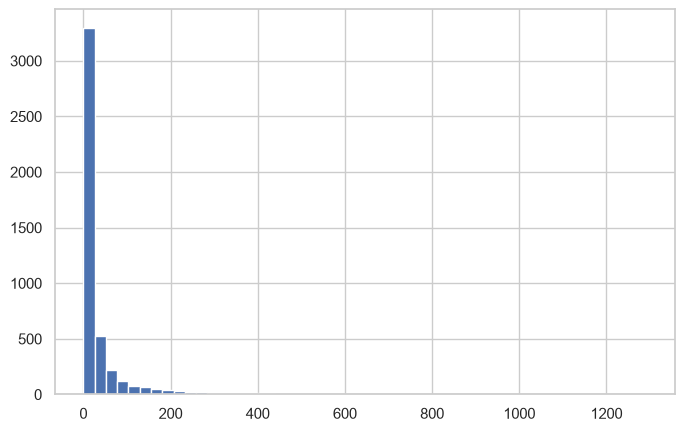

In [ ]:
# Load the table, parsing the dates
date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv("data/listings_clean.csv", parse_dates=date_columns)

# Same theme as in the lecture.
sns.set_theme(style="whitegrid")

# Draw a histogram with pure matplotlib
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(listings["number_of_reviews"], bins=50)
plt.show()

We can see one very tall bar on the left and a thin tail to 1293, but no title and no axis names.

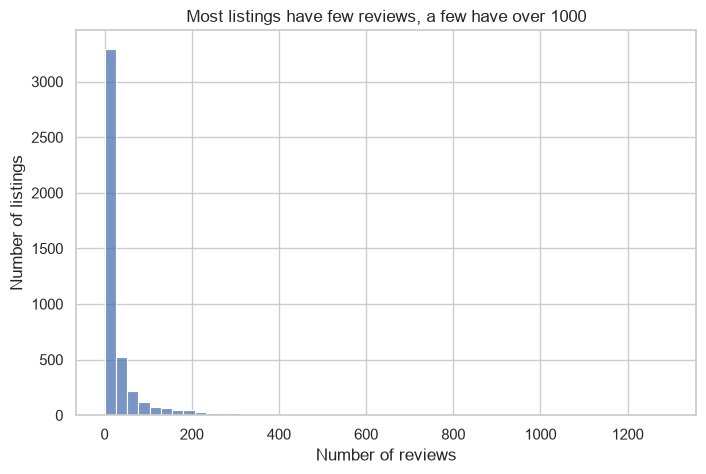

In [ ]:
# Draw the same diagram with Seaborn
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)
ax.set_title("Most listings have few reviews, a few have over 1000")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")
plt.show()

Seaborn: same shape, cleaner look, and we add a title and axis names.

#### Task 2: Mean, median and the fences

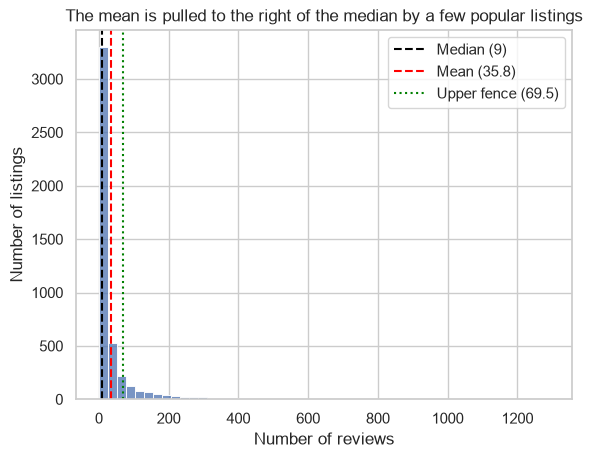

In [ ]:
reviews = listings["number_of_reviews"]

# Median, mean and the upper fence
median = reviews.median()
mean = reviews.mean()
q1, q3 = reviews.quantile(0.25), reviews.quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

# The histogram again, with one vertical line for each number.
fig, ax = plt.subplots()

sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)

ax.axvline(median, color="black", linestyle="--", label=f"Median ({median:.0f})")
ax.axvline(mean, color="red", linestyle="--", label=f"Mean ({mean:.1f})")
ax.axvline(upper, color="green", linestyle=':', label=f"Upper fence ({upper:.1f})")

ax.set_title("The mean is pulled to the right of the median by a few popular listings")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")
ax.legend()

plt.show()